In [1]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

6 possible layouts


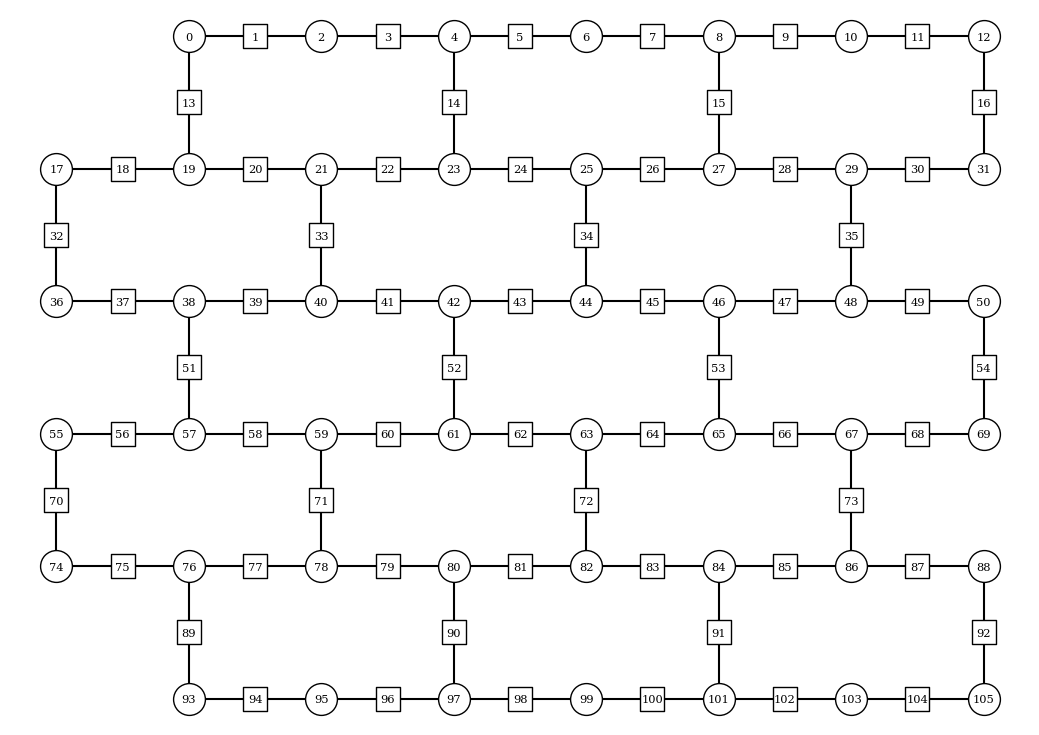

In [2]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 5

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

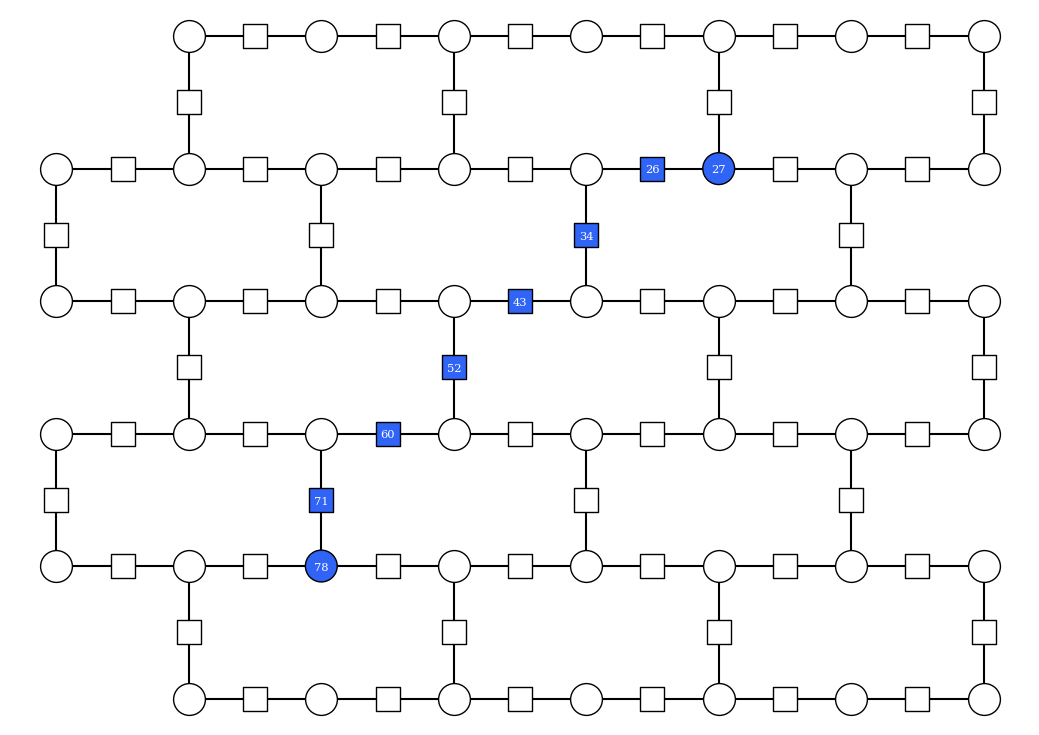

In [3]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB
from utils.execrecord import ExecutionRecord

lattice_dims = (plaquette_width, plaquette_height)
J = 0
h = 0
lamb = 1
g = 10

x_basis = False

fractional_gates = False

# string = [4, 14, 24, 34, 45, 53, 63]
string = [27, 26, 34, 43, 52, 60, 71, 78]

final_time = 5
dt = 0.5
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 150000
confidence = 0.7

odr = True
flip_threshold = None
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 5

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string))

In [4]:
from utils.postselection import load_postselected_jobs
import pickle
import os

overwrite = False
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_ft_{flip_threshold}.npy")
else:
    curated_data_filepath = None

if overwrite or not os.path.exists(curated_data_filepath):
    if odr:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True)
    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

In [15]:
maxcounts = max(postselected_samples_dicts[0][0][1].values())

for k,v in postselected_samples_dicts[0][0][1].items():
    if v == maxcounts:
        mk = k

In [40]:
"0000000000000000000000000001000000100000000001000000010000000010000000010000001100000000000000000000000000" == mk

False

In [17]:
mk

'0000000000001000100000000001010000100000000001000000010000000010000000010000001100000000000000000000000000'

In [34]:
from utils.postselection import combine_samples_dicts

csamples = combine_samples_dicts(*[postselected_samples_dicts[0][j][3] for j in range(len(postselected_samples_dicts[0]))])

In [35]:
maxcounts = max(csamples.values())

for k,v in csamples.items():
    if v == maxcounts:
        mk = k

In [36]:
mk

'0000111000000000000000000000000000000000000001100000010000000010000000010000001100000000000000000000000000'

In [37]:
"0000000000000000000000000001000000100000000001000000010000000010000000010000001100000000000000000000000000" == mk

False

In [38]:
csamples[mk]

3

In [39]:
1742/150000

0.011613333333333333